# 20. ARIMA / ARIMAX: dự báo SOH từ lịch sử của chính pin (Chap 5)

**Người làm:** Tiến Hưng · **Review:** Quốc Đạt · **Branch:** `tien-hung` · **WBS:** C5.1–C5.7 · **RQ3**

Notebook đi theo quy trình Box-Jenkins (Chap 5): vẽ chuỗi → kiểm tra tính dừng → nhận dạng (p, d, q) → ước lượng → chẩn đoán phần dư → dự báo.
Dữ liệu, cách chia train/test và cách chấm điểm lấy từ `src/protocol.py` (Rec.md mục 6 và 6.1), để kết quả so được với naive, hồi quy, SVR và LSTM.

| Quy ước | Giá trị |
|---|---|
| Chuỗi | `soh` theo thứ tự dòng (`cycle_valid` tăng dần) của từng pin tier A, đã bỏ `cap_outlier` và `break_in` (Rec.md 6.1 #4) |
| Trục thời gian | số thứ tự chu kỳ, không dùng ngày, vì khoảng nghỉ giữa các chu kỳ không đều (Chap 5, tr. 4) |
| Phân tích Box-Jenkins (mục 1–5) | 8 pin **train**, cả chuỗi; pin test chỉ được nhìn phần trước mốc 60% |
| Dự báo (mục 6–7) | mỗi pin test: fit trên 60% dòng đầu của chính pin đó, dự báo 40% còn lại theo E1 và E2 |

Chạy từ thư mục gốc repo hoặc từ `notebooks/` (Restart & Run All).

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tools.sm_exceptions import ConvergenceWarning, ValueWarning
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import acf, adfuller

ROOT = Path.cwd().resolve()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
from protocol import EOL_SOH, KEYS, PRED, PRED_COLS, evaluate, load_split  # noqa: E402

FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
# Hội tụ của từng lần fit được ghi lại trong cột `converged`, nên chỉ ẩn cảnh báo lặp lại của statsmodels
warnings.filterwarnings("ignore", category=ConvergenceWarning)
warnings.filterwarnings("ignore", category=ValueWarning)
warnings.filterwarnings("ignore", message=".*Non-stationary starting autoregressive.*")
warnings.filterwarnings("ignore", message=".*Non-invertible starting MA.*")
warnings.filterwarnings("ignore", message=".*adfuller currently returns a plain tuple.*", category=FutureWarning)
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

train, test = load_split()
rows = pd.concat([train.assign(set="train"), test.assign(set="test")], ignore_index=True)
rows["log_rest"] = np.log1p(rows.rest_before_h)
TRAIN_IDS = sorted(train.battery_id.unique())
TEST_IDS = sorted(test.battery_id.unique())
print(f"train {len(train)} dòng / {len(TRAIN_IDS)} pin; test {len(test)} dòng / {len(TEST_IDS)} pin; "
      f"dòng đánh giá {int(test.is_eval.sum())}")

train 947 dòng / 8 pin; test 528 dòng / 4 pin; dòng đánh giá 213


## 1. Vẽ chuỗi SOH của từng pin tier A (C5.1, Chap 5 tr. 5–6)

Bảng dưới tóm tắt từng chuỗi. `n_long_rest` là số chu kỳ đứng sau một lần nghỉ dài (cờ `long_rest` trong `cycles_clean.csv`).
Với pin test, các cột `n_pre` / `n_eval` là số dòng trước mốc 60% (dùng để fit) và số dòng đánh giá.

In [2]:
summary = rows.groupby("battery_id").agg(
    set=("set", "first"), ambient_C=("ambient_C", "first"), I_level_A=("I_level_A", "first"),
    cutoff_V=("discharge_cutoff_V", "first"), n=("soh", "size"),
    soh_first=("soh", "first"), soh_last=("soh", "last"), soh_min=("soh", "min"),
    n_long_rest=("long_rest", "sum"))
pre_eval = test.groupby("battery_id").is_eval.agg(n_pre=lambda s: int((~s).sum()), n_eval="sum")
summary = summary.join(pre_eval)
summary.round(3)

,set,ambient_C,I_level_A,cutoff_V,n,soh_first,soh_last,soh_min,n_long_rest,n_pre,n_eval
battery_id,,,,,,,,,,,
B0005,train,24.0,2.0,2.7,167,1.005,0.717,0.697,8,NaN,NaN
B0006,train,24.0,2.0,2.5,166,1.005,0.591,0.576,8,NaN,NaN
B0007,test,24.0,2.0,2.2,167,1.005,0.763,0.746,8,100.0,67.0
B0018,train,24.0,2.0,2.5,132,1.006,0.733,0.733,0,NaN,NaN
B0033,train,24.0,4.0,2.0,178,1.025,0.786,0.783,5,NaN,NaN
B0034,test,24.0,4.0,2.2,194,1.009,0.808,0.799,6,116.0,78.0
B0045,train,4.0,1.0,2.0,67,1.041,0.727,0.724,6,NaN,NaN
B0046,train,4.0,1.0,2.2,68,1.011,0.795,0.777,6,NaN,NaN
B0047,test,4.0,1.0,2.5,68,1.011,0.776,0.744,6,40.0,28.0


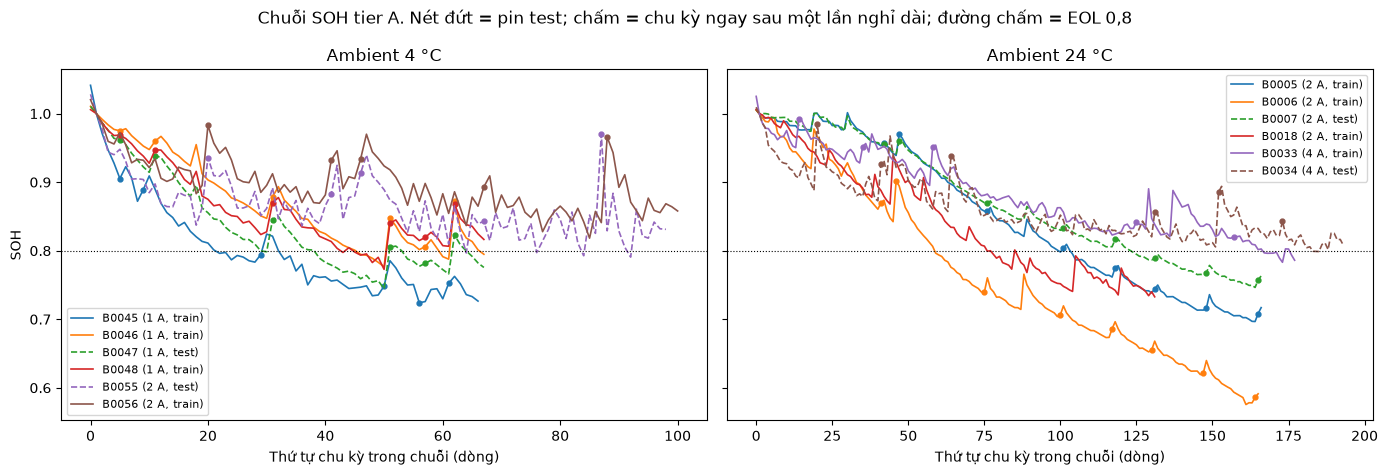

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), sharey=True)
for ax, (amb, grp) in zip(axes, rows.groupby("ambient_C")):
    for b, g in grp.groupby("battery_id"):
        style = "-" if g.set.iloc[0] == "train" else "--"
        line, = ax.plot(np.arange(len(g)), g.soh, style, lw=1.2,
                        label=f"{b} ({g.I_level_A.iloc[0]:.0f} A, {g.set.iloc[0]})")
        lr = np.flatnonzero(g.long_rest.values)
        ax.plot(lr, g.soh.values[lr], "o", ms=3.5, color=line.get_color())
    ax.axhline(EOL_SOH, color="k", lw=0.8, ls=":")
    ax.set_title(f"Ambient {amb:.0f} °C")
    ax.set_xlabel("Thứ tự chu kỳ trong chuỗi (dòng)")
    ax.legend(fontsize=8)
axes[0].set_ylabel("SOH")
fig.suptitle("Chuỗi SOH tier A. Nét đứt = pin test; chấm = chu kỳ ngay sau một lần nghỉ dài; đường chấm = EOL 0,8")
fig.tight_layout()
fig.savefig(FIG / "arima_01_series.png", dpi=150)
plt.show()

**Nhận xét (C5.1):**
- **Xu hướng (trend):** mọi chuỗi đều giảm dần theo chu kỳ, nên chuỗi gốc không dừng về trung bình.
- **Hồi phục (regeneration):** các chấm (chu kỳ ngay sau nghỉ dài) thường nằm cao hơn hẳn điểm trước đó, rồi SOH lại rơi nhanh về đường xu hướng.
  Đây là hiện tượng hồi phục dung lượng sau khi nghỉ (F5), là lý do đưa `log1p(rest_before_h)` vào ARIMAX ở mục 6.
- **Mùa vụ:** các lần nghỉ dài xảy ra ở những vị trí không đều nhau, nên không thấy chu kỳ lặp cố định. Mục 5 kiểm tra lại bằng ACF.

## 2. Tính dừng: ADF và ACF (C5.2, Chap 5 tr. 11–14, tr. 71)

Kiểm định ADF, H0: chuỗi có nghiệm đơn vị (không dừng). Chạy trên chuỗi gốc với hai dạng hồi quy, `c` (hằng số) và `ct` (hằng số + xu hướng),
rồi trên chuỗi sai phân bậc 1 `Δsoh` với dạng `c`. Số lag chọn theo AIC (`autolag="AIC"`).
Pin train dùng cả chuỗi; pin test chỉ dùng phần trước mốc 60% (đúng phần dữ liệu được fit).

In [4]:
def pre_origin(b):
    g = rows[rows.battery_id == b]
    return g if g.set.iloc[0] == "train" else g[~g.is_eval.astype(bool)]


adf_rows = []
for b in TRAIN_IDS + TEST_IDS:
    y = pre_origin(b).soh.to_numpy()
    r_c, r_ct, r_d = adfuller(y, regression="c"), adfuller(y, regression="ct"), adfuller(np.diff(y), regression="c")
    adf_rows.append({"battery_id": b, "set": rows.loc[rows.battery_id == b, "set"].iloc[0], "n": len(y),
                     "ADF_level_c": r_c[0], "p_level_c": r_c[1], "ADF_level_ct": r_ct[0], "p_level_ct": r_ct[1],
                     "ADF_diff": r_d[0], "p_diff": r_d[1]})
adf_table = pd.DataFrame(adf_rows)
adf_table["level_stationary_5pct"] = (adf_table.p_level_c < 0.05) & (adf_table.p_level_ct < 0.05)
adf_table["diff_stationary_5pct"] = adf_table.p_diff < 0.05
adf_table.round(4)

,battery_id,set,n,ADF_level_c,p_level_c,ADF_level_ct,p_level_ct,ADF_diff,p_diff,level_stationary_5pct,diff_stationary_5pct
0,B0005,train,167,-0.5349,0.8850,-1.8906,0.6595,-10.6818,0.0,False,True
1,B0006,train,166,-1.4503,0.5580,-2.8460,0.1806,-9.6915,0.0,False,True
2,B0018,train,132,-1.5107,0.5282,-3.4549,0.0445,-8.3744,0.0,False,True
3,B0033,train,178,-1.1482,0.6955,-2.9622,0.1430,-6.0435,0.0,False,True
4,B0045,train,67,-4.2728,0.0005,-4.3472,0.0027,-7.5565,0.0,True,True
5,B0046,train,68,-1.6886,0.4370,-2.9116,0.1585,-7.5728,0.0,False,True
6,B0048,train,68,-2.3247,0.1641,-2.2259,0.4753,-8.8342,0.0,False,True
7,B0056,train,101,-2.5407,0.1059,-5.5342,0.0000,-7.4616,0.0,False,True
8,B0007,test,100,0.1556,0.9697,-2.4257,0.3660,-8.3317,0.0,False,True
9,B0034,test,116,-1.9416,0.3128,-3.9622,0.0099,-8.1040,0.0,False,True


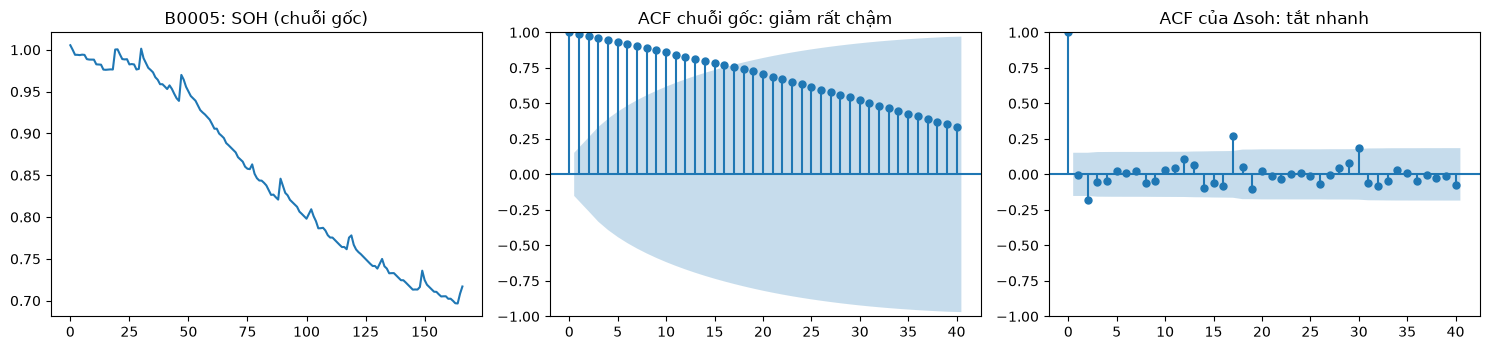

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
y5 = rows.loc[rows.battery_id == "B0005", "soh"].to_numpy()
axes[0].plot(y5)
axes[0].set_title("B0005: SOH (chuỗi gốc)")
plot_acf(y5, lags=40, ax=axes[1], title="ACF chuỗi gốc: giảm rất chậm")
plot_acf(np.diff(y5), lags=40, ax=axes[2], title="ACF của Δsoh: tắt nhanh")
fig.tight_layout()
fig.savefig(FIG / "arima_02_acf_level_vs_diff.png", dpi=150)
plt.show()

**Kết luận về d:** ACF của chuỗi gốc giảm rất chậm, đúng dấu hiệu của chuỗi không dừng (tr. 13). Sau sai phân bậc 1, ACF tắt gần như ngay và ADF bác bỏ H0
ở mọi pin (cột `diff_stationary_5pct`). Một vài chuỗi ngắn có ADF trên chuỗi gốc cũng nhỏ hơn 0,05 (xem cột `level_stationary_5pct`): đó là các pin
4 °C ngắn và có nhiều bước nhảy hồi phục lớn, nên ADF dễ bị nhiễu. Vì xu hướng giảm thấy rõ trên mọi chuỗi và ACF gốc giảm chậm, nhóm **chốt d = 1 cho mọi pin**
để dùng cùng một dạng mô hình. Không cần d = 2, vì `Δsoh` đã dừng.

## 3. Nhận dạng (p, q) bằng ACF/PACF và lưới AIC (C5.3, Chap 5 tr. 47, 65–67)

Đọc ACF/PACF của `Δsoh` trên 8 pin train: PACF cắt sau lag p gợi ý AR(p), ACF cắt sau lag q gợi ý MA(q).

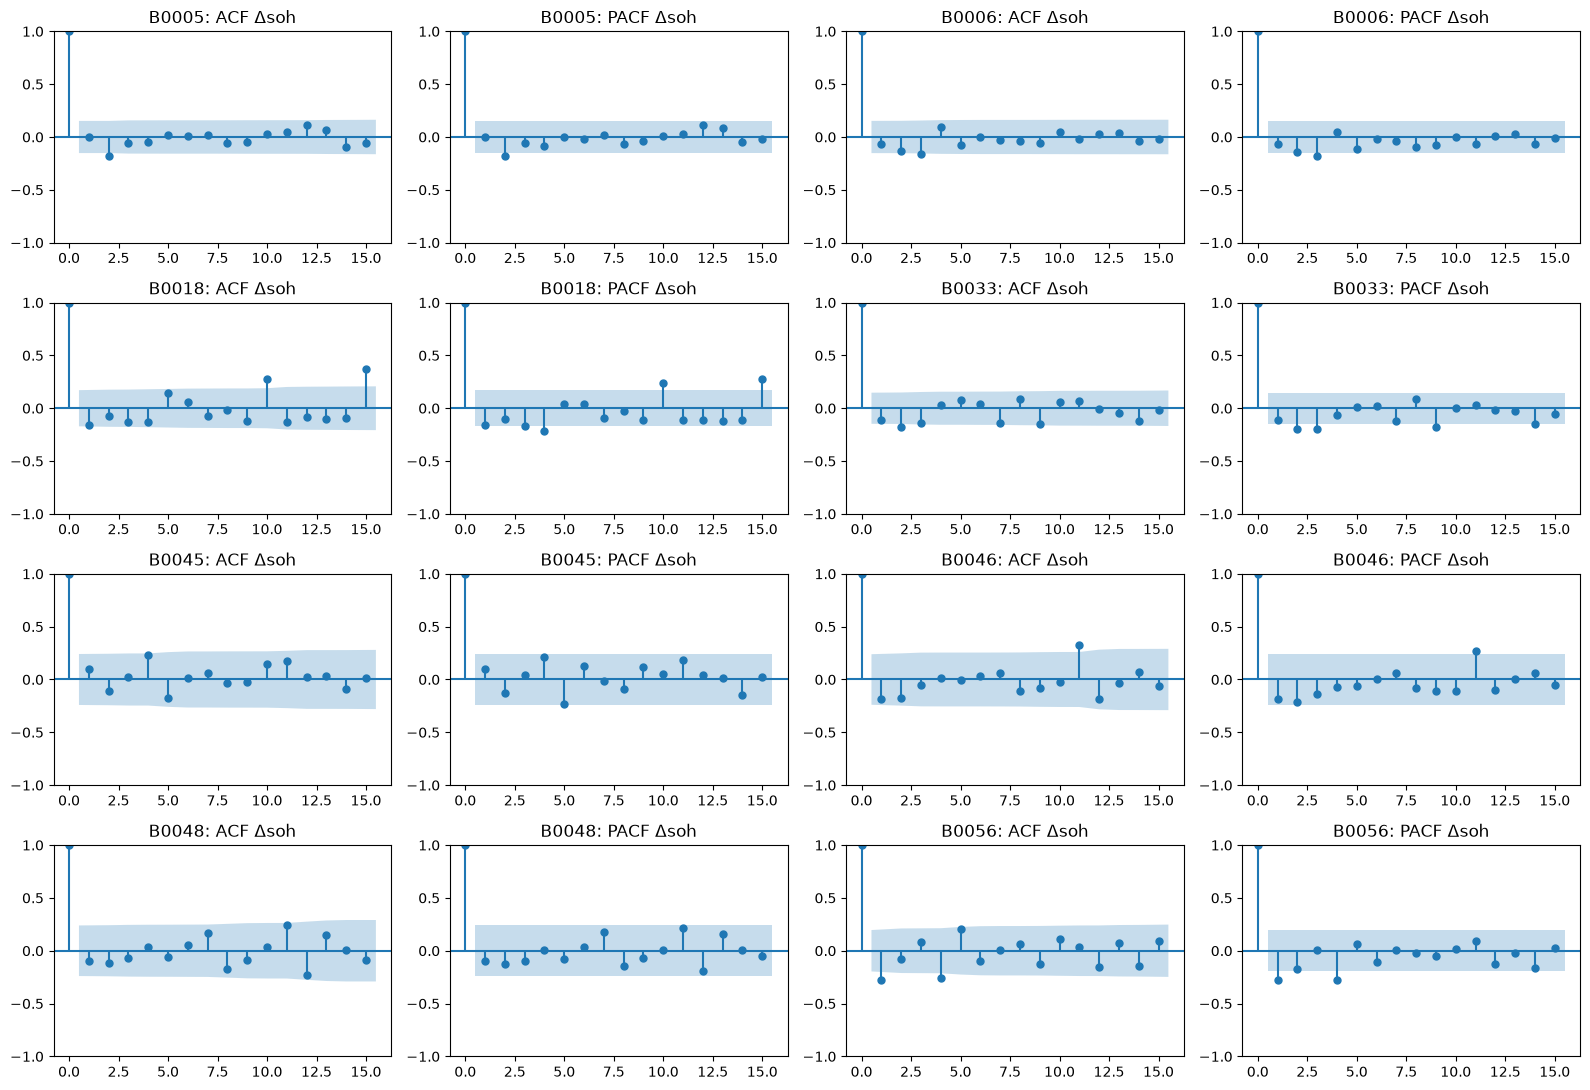

In [6]:
fig, axes = plt.subplots(4, 4, figsize=(16, 11))
for i, b in enumerate(TRAIN_IDS):
    d = np.diff(rows.loc[rows.battery_id == b, "soh"].to_numpy())
    plot_acf(d, lags=15, ax=axes[i // 2, (i % 2) * 2], title=f"{b}: ACF Δsoh")
    plot_pacf(d, lags=15, ax=axes[i // 2, (i % 2) * 2 + 1], title=f"{b}: PACF Δsoh", method="ywm")
fig.tight_layout()
fig.savefig(FIG / "arima_03_acf_pacf_diff.png", dpi=150)
plt.show()

Đồ thị trên chỉ gợi ý bậc thấp: các đỉnh nổi bật nếu có thường ở lag 1, đôi khi lag 2. Vì vậy dò lưới **p, q ∈ {0, 1, 2}, d = 1** và chọn theo **AIC** (tr. 67).
Thêm một lựa chọn về hằng số: `trend="n"` (không drift) và `trend="t"` (có drift, tức `Δsoh` có trung bình khác 0). Drift là cách duy nhất để
ARIMA với d = 1 dự báo xu hướng giảm khi đi xa nhiều bước (E2); không có drift thì dự báo nhiều bước gần như đi ngang.

Tổng cộng 3 × 3 × 2 = 18 mô hình mỗi chuỗi, ước lượng bằng MLE (`statsmodels.tsa.arima.model.ARIMA`, tr. 48). Chỉ nhận mô hình có tối ưu hội tụ.

In [7]:
GRID = [(p, q, tr) for p in range(3) for q in range(3) for tr in ("n", "t")]


def fit_arima(y, order, trend, exog=None):
    return ARIMA(y, exog=exog, order=order, trend=trend).fit()


def aic_grid(y, exog=None):
    out = []
    for p, q, tr in GRID:
        try:
            res = fit_arima(y, (p, 1, q), tr, exog)
            out.append({"p": p, "d": 1, "q": q, "trend": tr, "AIC": res.aic, "BIC": res.bic,
                        "converged": bool(res.mle_retvals.get("converged", True))})
        except Exception as e:  # ghi lại thay vì bỏ qua lặng lẽ
            out.append({"p": p, "d": 1, "q": q, "trend": tr, "AIC": np.nan, "BIC": np.nan, "converged": False,
                        "error": str(e)[:60]})
    return pd.DataFrame(out).sort_values("AIC").reset_index(drop=True)


def best_spec(grid):
    ok = grid[grid.converged & grid.AIC.notna()]
    top = ok.iloc[0]
    return (int(top.p), 1, int(top.q)), top.trend


grids = {b: aic_grid(rows.loc[rows.battery_id == b, "soh"].to_numpy()) for b in TRAIN_IDS}
print("Lưới AIC đầy đủ của B0005 (sắp theo AIC):")
grids["B0005"].round(2)

Lưới AIC đầy đủ của B0005 (sắp theo AIC):


,p,d,q,trend,AIC,BIC,converged
0,0,1,2,t,-1229.51,-1217.06,False
1,2,1,0,t,-1228.33,-1215.88,True
2,1,1,2,t,-1228.20,-1212.64,True
3,2,1,1,t,-1227.63,-1212.07,True
4,0,1,0,t,-1226.40,-1220.17,True
5,2,1,2,t,-1226.18,-1207.51,True
6,1,1,0,t,-1224.40,-1215.06,True
7,0,1,1,t,-1224.38,-1215.05,True
8,1,1,1,t,-1222.84,-1210.39,True
9,0,1,0,n,-1214.79,-1211.68,False


In [8]:
train_specs = []
for b in TRAIN_IDS:
    g = grids[b]
    order, tr = best_spec(g)
    second = g[g.converged].iloc[1]
    train_specs.append({"battery_id": b, "n": int((rows.battery_id == b).sum()), "p": order[0], "d": 1, "q": order[2],
                        "trend": tr, "AIC": g[g.converged].AIC.iloc[0],
                        "AIC_2nd": second.AIC, "2nd": f"({int(second.p)},1,{int(second.q)}) {second.trend}",
                        "n_not_converged": int((~g.converged).sum())})
train_specs = pd.DataFrame(train_specs)
train_specs.round(2)

,battery_id,n,p,d,q,trend,AIC,AIC_2nd,2nd,n_not_converged
0,B0005,167,2,1,0,t,-1228.33,-1228.20,"(1,1,2) t",3
1,B0006,166,1,1,1,t,-1052.17,-1048.52,"(0,1,2) t",2
2,B0018,132,1,1,2,t,-794.25,-794.12,"(1,1,1) t",1
3,B0033,178,2,1,1,t,-1085.54,-1085.50,"(1,1,2) t",4
4,B0045,67,0,1,0,t,-363.87,-362.78,"(0,1,1) t",7
5,B0046,68,0,1,2,t,-349.31,-348.16,"(0,1,1) t",2
6,B0048,68,0,1,0,t,-363.05,-362.90,"(0,1,0) n",1
7,B0056,101,1,1,2,n,-448.45,-447.53,"(1,1,2) t",1


## 4. Chẩn đoán phần dư: ACF và Ljung-Box (C5.4, Chap 5 tr. 49)

Mô hình tốt thì phần dư phải là nhiễu trắng. Kiểm định **Ljung-Box** (mở rộng ngoài slide), H0: phần dư không tự tương quan đến lag h.
Chạy ở h = 10 và h = 20, bậc tự do trừ đi p + q (`model_df`). Bỏ phần dư đầu tiên vì với d = 1 nó chỉ là giá trị khởi tạo (bằng chính `soh` đầu chuỗi).

**Quy tắc chọn cuối cùng** (vòng lặp Box-Jenkins, tr. 49 "nếu chưa đạt thì quay lại nhận dạng"): đi theo thứ tự AIC tăng dần trong lưới, lấy mô hình **đầu tiên**
vừa hội tụ vừa có Ljung-Box p > 0,05 ở cả lag 10 và 20. Nếu không mô hình nào đạt thì giữ mô hình AIC nhỏ nhất và đánh dấu `LB_pass = False`.
Quy tắc này dùng lại nguyên vẹn cho pin test ở mục 6.

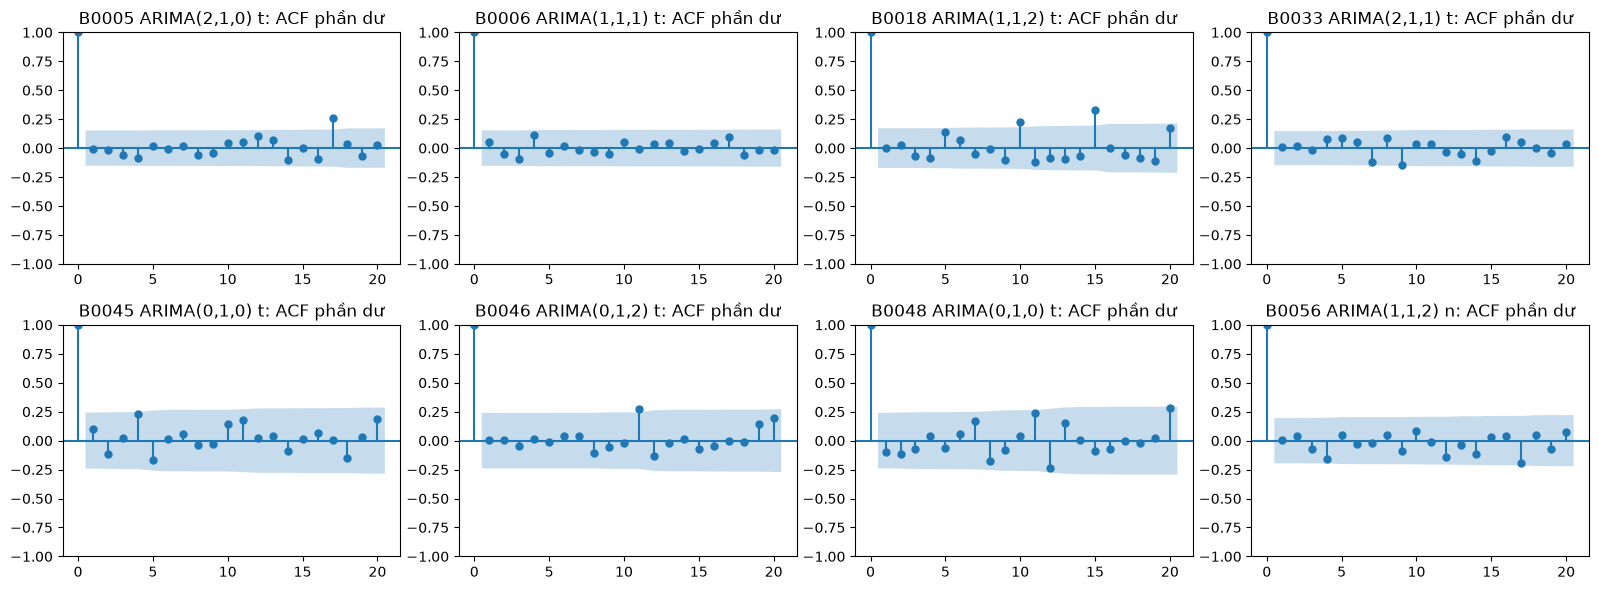

,battery_id,order,trend,AIC,LB_p_lag10,LB_p_lag20,aic_rank,LB_pass,resid_sd
0,B0005,"(2,1,0)",t,-1228.3252,0.9150,0.1504,1,True,0.0059
1,B0006,"(1,1,1)",t,-1052.1708,0.6585,0.9469,1,True,0.0098
2,B0018,"(1,1,2)",t,-794.2525,0.0408,0.0003,1,False,0.0113
3,B0033,"(2,1,1)",t,-1085.5423,0.1013,0.3573,1,True,0.0110
4,B0045,"(0,1,0)",t,-363.8687,0.4669,0.5286,1,True,0.0150
5,B0046,"(0,1,2)",t,-349.3110,0.9917,0.5936,1,True,0.0169
6,B0048,"(0,1,0)",t,-363.0527,0.6439,0.1020,1,True,0.0158
7,B0056,"(1,1,2)",n,-448.4457,0.5606,0.4876,1,True,0.0246


In [9]:
def ljung_box(res, p, q, lags=(10, 20)):
    resid = np.asarray(res.resid)[1:]
    lb = acorr_ljungbox(resid, lags=list(lags), model_df=p + q)
    return {f"LB_p_lag{h}": lb.loc[h, "lb_pvalue"] for h in lags}


def select(y, exog=None, grid=None):
    """Return (res, order, trend, info): lowest-AIC converged model whose residuals pass Ljung-Box."""
    grid = aic_grid(y, exog) if grid is None else grid
    ok = grid[grid.converged & grid.AIC.notna()].reset_index(drop=True)
    first = None
    for rank, r in ok.iterrows():
        order, tr = (int(r.p), 1, int(r.q)), r.trend
        res = fit_arima(y, order, tr, exog)
        lb = ljung_box(res, order[0], order[2])
        passed = all(v > 0.05 for v in lb.values())
        first = first or (res, order, tr, {**lb, "aic_rank": rank + 1, "LB_pass": passed})
        if passed:
            return res, order, tr, {**lb, "aic_rank": rank + 1, "LB_pass": True}
    return first


diag = []
chosen = {}
fig, axes = plt.subplots(2, 4, figsize=(16, 6))
for ax, b in zip(axes.flat, TRAIN_IDS):
    y = rows.loc[rows.battery_id == b, "soh"].to_numpy()
    res, order, tr, info = select(y, grid=grids[b])
    chosen[b] = (order, tr)
    diag.append({"battery_id": b, "order": f"({order[0]},1,{order[2]})", "trend": tr, "AIC": res.aic, **info,
                 "resid_sd": np.std(np.asarray(res.resid)[1:], ddof=1)})
    plot_acf(np.asarray(res.resid)[1:], lags=20, ax=ax,
             title=f"{b} ARIMA({order[0]},1,{order[2]}) {tr}: ACF phần dư")
fig.tight_layout()
fig.savefig(FIG / "arima_04_resid_acf_train.png", dpi=150)
plt.show()
diag = pd.DataFrame(diag)
diag.round(4)

`aic_rank = 1` nghĩa là mô hình AIC nhỏ nhất đã qua chẩn đoán. `aic_rank > 1` nghĩa là mô hình AIC nhỏ nhất còn tự tương quan trong phần dư,
nên đã quay lại lưới và lấy mô hình kế tiếp đạt yêu cầu (so với bảng ở mục 3).

## 5. Có cần SARIMA không? Seasonality và hiện tượng hồi phục (C5.6, Chap 5 tr. 60–62)

SARIMA chỉ có ích khi chuỗi lặp lại sau một số chu kỳ cố định s. Kiểm tra hai việc:
1. ACF của `Δsoh` đến lag 40 trên 8 pin train: có lag nào (ngoài lag 1–2) vượt dải tin cậy 95% ở **nhiều pin cùng lúc** không?
2. Khoảng cách (số chu kỳ) giữa hai lần nghỉ dài liên tiếp có cố định không? Nếu không cố định thì các "răng cưa" hồi phục không phải mùa vụ.

In [10]:
LAGS = 40
sig = {}
for b in TRAIN_IDS:
    d = np.diff(rows.loc[rows.battery_id == b, "soh"].to_numpy())
    r = acf(d, nlags=LAGS)
    band = 1.96 / np.sqrt(len(d))
    sig[b] = np.abs(r[1:]) > band
sig = pd.DataFrame(sig, index=range(1, LAGS + 1))
count = sig.sum(axis=1)
print("Số pin train (trên 8) có ACF(Δsoh) vượt dải ±1,96/√n, theo từng lag:")
print(count[count > 0].to_string())

gaps = []
for b in TRAIN_IDS:
    pos = np.flatnonzero(rows.loc[rows.battery_id == b, "long_rest"].to_numpy())
    gaps.append({"battery_id": b, "n_long_rest": len(pos), "gaps_between_long_rests": np.diff(pos).tolist()})
pd.DataFrame(gaps)

Số pin train (trên 8) có ACF(Δsoh) vượt dải ±1,96/√n, theo từng lag:
1     1
2     2
3     1
4     1
5     1
9     1
10    1
11    2
15    1
17    2
20    2
21    1
25    1
26    1
27    1
30    2
35    1
40    1


,battery_id,n_long_rest,gaps_between_long_rests
0,B0005,8,"[5, 29, 25, 17, 13, 17, 17]"
1,B0006,8,"[5, 29, 25, 17, 13, 17, 17]"
2,B0018,0,[]
3,B0033,5,"[21, 23, 67, 32]"
4,B0045,6,"[4, 20, 21, 6, 5]"
5,B0046,6,"[6, 20, 20, 6, 5]"
6,B0048,6,"[6, 20, 20, 6, 5]"
7,B0056,5,"[21, 5, 21, 21]"


In [11]:
reg = []
for b in TRAIN_IDS:
    g = rows[rows.battery_id == b]
    d = np.diff(g.soh.to_numpy())
    x = g.log_rest.to_numpy()[1:]
    lr = g.long_rest.to_numpy()[1:]
    reg.append({"battery_id": b, "n_long_rest": int(lr.sum()),
                "corr(Δsoh_t, log1p(rest_before_h)_t)": np.corrcoef(d, x)[0, 1],
                "mean Δsoh after long rest": d[lr].mean() if lr.any() else np.nan,
                "mean Δsoh otherwise": d[~lr].mean()})
pd.DataFrame(reg).round(4)

,battery_id,n_long_rest,"corr(Δsoh_t, log1p(rest_before_h)_t)",mean Δsoh after long rest,mean Δsoh otherwise
0,B0005,8,0.3779,0.0094,-0.0023
1,B0006,8,0.2856,0.0121,-0.0033
2,B0018,0,-0.1078,NaN,-0.0021
3,B0033,5,0.5091,0.0264,-0.0022
4,B0045,6,0.2790,0.0024,-0.0055
5,B0046,6,0.7200,0.0336,-0.0068
6,B0048,6,0.7806,0.0326,-0.0063
7,B0056,5,0.6200,0.0639,-0.0051


B0018 không có lần nghỉ dài nào (`n_long_rest = 0`) nhưng hình ở mục 1 vẫn có các bước nhảy. Bảng dưới đếm các **bước nhảy** (`Δsoh > 0,015`) của từng pin và xem chúng
đứng ngay sau một lần đo EIS mới (`eis_op_index` đổi so với dòng trước) hay sau một lần nghỉ dài. Ngưỡng 0,015 được chọn vì lớn hơn khoảng 2 lần độ lệch chuẩn
phần dư lớn nhất ở bảng mục 4 trên các pin 24 °C, nên chỉ bắt các bước nhảy rõ rệt.

In [12]:
JUMP = 0.015
jump_rows = []
for b in TRAIN_IDS + TEST_IDS:
    g = pre_origin(b).reset_index(drop=True)          # pin test: chỉ phần trước mốc
    big = set((np.flatnonzero(np.diff(g.soh.to_numpy()) > JUMP) + 1).tolist())
    new_eis = set(np.flatnonzero(g.eis_op_index.diff().fillna(0).to_numpy() != 0).tolist())
    lr = set(np.flatnonzero(g.long_rest.to_numpy()).tolist())
    jump_rows.append({"battery_id": b, "n": len(g), "n_new_EIS": len(new_eis), "n_jumps": len(big),
                      "jumps_after_new_EIS": len(big & new_eis), "jumps_after_long_rest": len(big & lr),
                      "jumps_after_neither": len(big - new_eis - lr)})
pd.DataFrame(jump_rows)

,battery_id,n,n_new_EIS,n_jumps,jumps_after_new_EIS,jumps_after_long_rest,jumps_after_neither
0,B0005,167,139,5,3,1,1
1,B0006,166,138,5,2,1,2
2,B0018,132,48,9,8,0,1
3,B0033,178,41,7,6,3,1
4,B0045,67,18,7,6,2,1
5,B0046,68,18,4,3,3,1
6,B0048,68,18,5,4,4,1
7,B0056,101,23,24,13,5,10
8,B0007,100,76,4,2,1,1
9,B0034,116,26,9,9,3,0


Ở B0018, các bước nhảy đi kèm lần đo EIS chứ không đi kèm thời gian nghỉ (thời gian nghỉ ghi trong dữ liệu ở những chu kỳ đó rất ngắn), nên `log1p(rest_before_h)`
không giải thích được chúng. Đây là lý do hợp lý nhất cho việc phần dư của B0018 còn tự tương quan ở mục 4 (các bước nhảy cách nhau khá đều). Với B0005–B0007, EIS được đo
gần như mỗi chu kỳ nên cờ "vừa đo EIS" không phân biệt được gì. Ghi nhận này được chuyển cho nhóm như một hướng cải tiến (biến cờ "vừa đo EIS"), **không** đưa vào
mô hình xuất file, vì danh sách biến của ARIMAX đã chốt ở Go.md 5b.8.

**Kết luận C5.6:** (đọc cùng các bảng trên)
- Không có lag mùa vụ nào nổi bật ở đa số pin; các lag vượt dải nằm rải rác, mỗi lag chỉ ở một vài pin, đúng mức kỳ vọng do ngẫu nhiên khi xét 40 lag ở mức 5%.
- Khoảng cách giữa các lần nghỉ dài thay đổi giữa các lần và giữa các pin, nên không có chu kỳ s cố định để đưa vào SARIMA.
- Các "răng cưa" lại gắn chặt với thời gian nghỉ: `Δsoh` ngay sau nghỉ dài dương và lớn hơn hẳn các chu kỳ khác, và tương quan với `log1p(rest_before_h)` dương.

⇒ **Không dùng SARIMA.** Phần biến động có quy luật này được mô hình hoá bằng biến ngoại sinh `log1p(rest_before_h)` trong ARIMAX (mục 6), đúng hướng ở Go.md 5b.8–5b.9.

## 6. Ước lượng trên pin test, ARIMA và ARIMAX (C5.3–C5.5, Chap 5 tr. 48–53)

Với mỗi pin test, làm lại đúng quy trình trên **chỉ với 60% dòng đầu** của chính pin đó (cột `is_eval == False`), rồi dự báo 40% cuối.

| Mô hình | Biến ngoại sinh `x_t` | Lý do |
|---|---|---|
| `arima` | không có | Chỉ dùng lịch sử SOH (RQ3) |
| `arimax_rest` | `log1p(rest_before_h)` | Giải thích bước nhảy hồi phục (mục 5) |
| `arimax` | `log1p(rest_before_h)`, `Rct_ohm` | Theo Go.md 5b.8: thêm điện trở truyền điện tích, đo ở lần EIS gần nhất trước chu kỳ t |

Các quy tắc chung (Rec.md 6.1):
- `rest_before_h` của chu kỳ t là thời gian nghỉ **trước** khi xả t, nên đã biết ở thời điểm dự báo; `Rct_ohm` lấy từ lần đo trước. Cả hai nằm trong danh sách được phép (Go.md 4.6).
- `Rct_ohm` bị thiếu ở 19 chu kỳ đầu của B0007 (chưa có lần đo EIS nào). Theo Rec.md 6.1 #6, **bỏ các dòng đó, không điền**. Để AIC so được giữa ba mô hình,
  cả ba mô hình của B0007 đều fit trên cùng các dòng (từ dòng thứ 20). Ba pin test còn lại không thiếu giá trị nào.
- (p, q, trend) chọn bằng lưới AIC như mục 3, riêng cho từng pin và từng mô hình, chỉ trên phần trước mốc. Không dùng dữ liệu đánh giá để chọn mô hình.

In [13]:
SPECS = {"arima": [], "arimax_rest": ["log_rest"], "arimax": ["log_rest", "Rct_ohm"]}
NEED = ["log_rest", "Rct_ohm"]          # cùng một mẫu fit cho cả ba mô hình (Rec.md 6.1 #6)

fits = {}
spec_rows = []
for b in TEST_IDS:
    g = rows[rows.battery_id == b].reset_index(drop=True)
    is_eval = g.is_eval.astype(bool).to_numpy()
    first_ok = int(np.flatnonzero(g[NEED].notna().all(axis=1).to_numpy())[0])
    g = g.iloc[first_ok:].reset_index(drop=True)
    is_eval = is_eval[first_ok:]
    n_pre = int((~is_eval).sum())
    assert g[NEED].notna().all().all() and not is_eval[:n_pre].any() and is_eval[n_pre:].all()
    for name, cols in SPECS.items():
        y_pre = g.soh.iloc[:n_pre]
        x_pre = g[cols].iloc[:n_pre] if cols else None   # DataFrame: tham số mang đúng tên cột
        res, order, tr, info = select(y_pre, x_pre)
        fits[(b, name)] = {"g": g, "n_pre": n_pre, "cols": cols, "res": res, "order": order, "trend": tr}
        par = dict(zip(res.param_names, res.params))
        pv = dict(zip(res.param_names, res.pvalues))
        trend_name = [k for k in par if k not in cols and not k.startswith(("ar.", "ma.", "sigma2"))]
        row = {"battery_id": b, "model": name, "rows_dropped": first_ok, "n_fit": n_pre,
               "order": f"({order[0]},1,{order[2]})", "trend": tr, "AIC": res.aic, **info,
               "drift": par[trend_name[0]] if trend_name else 0.0}
        for c in cols:
            row[f"coef_{c}"], row[f"p_{c}"] = par[c], pv[c]
        spec_rows.append(row)
spec_table = pd.DataFrame(spec_rows)
spec_table.round(4)

,battery_id,model,rows_dropped,n_fit,order,trend,AIC,LB_p_lag10,LB_p_lag20,aic_rank,LB_pass,drift,coef_log_rest,p_log_rest,coef_Rct_ohm,p_Rct_ohm
0,B0007,arima,19,81,"(1,1,1)",t,-622.1826,0.6086,0.6080,1,True,-0.0022,NaN,NaN,NaN,NaN
1,B0007,arimax_rest,19,81,"(1,1,1)",t,-621.8606,0.5907,0.7214,1,True,-0.0021,0.0014,0.0309,NaN,NaN
2,B0007,arimax,19,81,"(0,1,0)",t,-629.4472,0.3468,0.6991,1,True,-0.0023,0.0010,0.0387,1.1788,0.0000
3,B0034,arima,0,116,"(2,1,2)",t,-607.6292,0.8854,0.6943,1,True,-0.0016,NaN,NaN,NaN,NaN
4,B0034,arimax_rest,0,116,"(2,1,2)",t,-673.1766,0.5004,0.4859,1,True,-0.0015,0.0118,0.0000,NaN,NaN
5,B0034,arimax,0,116,"(2,1,2)",n,-675.6072,0.2532,0.3191,1,True,0.0000,0.0115,0.0000,2.5221,0.1087
6,B0047,arima,0,40,"(0,1,1)",t,-227.6631,0.5473,0.1693,1,True,-0.0057,NaN,NaN,NaN,NaN
7,B0047,arimax_rest,0,40,"(0,1,0)",t,-236.4028,0.7413,0.5492,1,True,-0.0056,0.0038,0.0000,NaN,NaN
8,B0047,arimax,0,40,"(0,1,0)",t,-236.0496,0.2809,0.1602,1,True,-0.0050,0.0039,0.0000,-0.4535,0.2754
9,B0055,arima,0,59,"(0,1,1)",n,-255.2944,0.9711,0.8229,1,True,0.0000,NaN,NaN,NaN,NaN


Bảng trên là bảng mô hình theo từng pin (p, d, q, AIC) mà Go.md 5b yêu cầu.
- `drift`: mức thay đổi SOH trung bình mỗi chu kỳ mà mô hình học được (0 khi `trend = n`).
- `coef_*` / `p_*`: hệ số và p-value (kiểm định z của MLE) của biến ngoại sinh. Với d = 1, statsmodels đặt biến ngoại sinh vào phương trình **mức** (regression with ARIMA errors),
  nên hệ số `log_rest` dương nghĩa là chu kỳ nghỉ lâu hơn có SOH cao hơn, và khi thời gian nghỉ trở lại bình thường thì SOH rơi lại: đúng hình "răng cưa" hồi phục.
- `LB_p_lag*`, `aic_rank`, `LB_pass`: chẩn đoán phần dư theo quy tắc ở mục 4, tính trên mẫu fit.

## 7. Dự báo theo giao thức chung, E1 và E2 (C5.7, Chap 5 tr. 49)

- **E1 (một bước, cuốn chiếu):** giữ nguyên tham số đã ước lượng trên 60% đầu, chạy bộ lọc Kalman qua cả chuỗi (`res.apply(..., refit=False)`) và lấy
  dự báo một bước cho từng dòng đánh giá. Dự báo tại t chỉ dùng `soh` đến t−1 (và `x_t`, vốn đã biết trước khi xả). Không ước lượng lại tham số theo từng bước,
  để mô hình không "học" thêm từ dữ liệu đánh giá; đây là cùng điều kiện với SVR/LSTM (fit một lần, dự báo nhiều lần).
- **E2 (nhiều bước từ mốc 60%):** `get_forecast` một mạch đến hết chuỗi. Biến ngoại sinh giữ nguyên giá trị đo cuối cùng trước mốc (Rec.md 6.1 #5).
- Cả hai kịch bản đều xuất khoảng dự báo 95% vào `y_lower`, `y_upper`.

In [14]:
def forecasts(f):
    g, n_pre, cols, res = f["g"], f["n_pre"], f["cols"], f["res"]
    y_all = g.soh
    x_all = g[cols] if cols else None
    n_eval = len(g) - n_pre
    one = res.apply(y_all, exog=x_all, refit=False).get_prediction(start=n_pre, end=len(g) - 1).summary_frame(alpha=0.05)
    x_hold = (pd.DataFrame(np.repeat(x_all.iloc[[n_pre - 1]].to_numpy(), n_eval, axis=0), columns=cols,
                           index=range(n_pre, len(g))) if cols else None)
    multi = res.get_forecast(steps=n_eval, exog=x_hold).summary_frame(alpha=0.05)
    ev = g.iloc[n_pre:]
    out = []
    for scenario, sf in (("E1", one), ("E2", multi)):
        out.append(pd.DataFrame({"battery_id": ev.battery_id.to_numpy(), "cycle_valid": ev.cycle_valid.to_numpy(),
                                 "scenario": scenario, "y_true": ev.soh.to_numpy(), "y_pred": sf["mean"].to_numpy(),
                                 "y_lower": sf["mean_ci_lower"].to_numpy(), "y_upper": sf["mean_ci_upper"].to_numpy()}))
    return pd.concat(out, ignore_index=True)


all_pred = pd.concat([forecasts(f).assign(model=name) for (b, name), f in fits.items()], ignore_index=True)[PRED_COLS]
metrics, rul = evaluate(all_pred)        # evaluate() kiểm tra đủ đúng 213 dòng đánh giá và y_true = soh cho từng mô hình
naive_pred = pd.read_csv(PRED / "naive.csv")
naive_metrics, naive_rul = evaluate(naive_pred)
metrics = pd.concat([naive_metrics, metrics], ignore_index=True)
rul = pd.concat([naive_rul, rul], ignore_index=True)

pooled = metrics[metrics.battery_id == "all"].pivot(index="model", columns="scenario", values=["MAE", "RMSE", "MAPE_pct", "R2"])
pooled = pooled.loc[["naive", "arima", "arimax_rest", "arimax"]]
pooled.round(4)

MAE            RMSE         MAPE_pct              R2        
scenario         E1      E2      E1      E2       E1      E2      E1      E2
model                                                                       
naive        0.0119  0.0249  0.0226  0.0343   1.4288  3.1271  0.5001 -0.1552
arima        0.0102  0.0458  0.0199  0.0589   1.2275  5.6648  0.6118 -2.4001
arimax_rest  0.0095  0.0442  0.0168  0.0570   1.1453  5.4629  0.7237 -2.1868
arimax       0.0098  0.0398  0.0170  0.0577   1.1850  4.9161  0.7155 -2.2602

In [15]:
per_bat = metrics[metrics.battery_id != "all"].pivot_table(index=["scenario", "battery_id"], columns="model", values="RMSE")
per_bat = per_bat[["naive", "arima", "arimax_rest", "arimax"]]
print("RMSE theo pin (hàng) và mô hình (cột)")
per_bat.round(4)

RMSE theo pin (hàng) và mô hình (cột)


model                 naive   arima  arimax_rest  arimax
scenario battery_id                                     
E1       B0007       0.0037  0.0045       0.0045  0.0049
         B0034       0.0135  0.0131       0.0115  0.0121
         B0047       0.0172  0.0181       0.0145  0.0139
         B0055       0.0462  0.0389       0.0326  0.0330
E2       B0007       0.0515  0.0360       0.0348  0.0402
         B0034       0.0179  0.0689       0.0656  0.0185
         B0047       0.0199  0.0932       0.0917  0.0812
         B0055       0.0305  0.0313       0.0320  0.0987

In [16]:
cover = all_pred.assign(inside=(all_pred.y_true >= all_pred.y_lower) & (all_pred.y_true <= all_pred.y_upper),
                        width=all_pred.y_upper - all_pred.y_lower)
coverage = cover.groupby(["model", "scenario"]).agg(coverage_95=("inside", "mean"), mean_width=("width", "mean"))
print("Tỉ lệ giá trị thực nằm trong khoảng dự báo 95% và độ rộng trung bình của khoảng")
coverage.round(3)

Tỉ lệ giá trị thực nằm trong khoảng dự báo 95% và độ rộng trung bình của khoảng


coverage_95  mean_width
model       scenario                         
arima       E1              0.944       0.054
            E2              0.742       0.190
arimax      E1              0.925       0.045
            E2              0.934       0.194
arimax_rest E1              0.925       0.046
            E2              0.732       0.184

In [17]:
print("Sai số RUL ở E2 (chu kỳ đầu tiên SOH < 0,8; rul_error > 0 là cảnh báo trễ; NaN = dự báo không chạm 0,8 trong phạm vi dữ liệu)")
rul.round(1)

Sai số RUL ở E2 (chu kỳ đầu tiên SOH < 0,8; rul_error > 0 là cảnh báo trễ; NaN = dự báo không chạm 0,8 trong phạm vi dữ liệu)


,model,battery_id,eol_true,eol_pred,rul_error
0,naive,B0007,126.0,NaN,NaN
1,naive,B0034,186.0,NaN,NaN
2,naive,B0055,65.0,NaN,NaN
3,arima,B0007,126.0,115.0,-11.0
4,arima,B0034,186.0,137.0,-49.0
5,arima,B0055,65.0,NaN,NaN
6,arimax,B0007,126.0,116.0,-10.0
7,arimax,B0034,186.0,NaN,NaN
8,arimax,B0055,65.0,71.0,6.0
9,arimax_rest,B0007,126.0,116.0,-10.0


### Hình dự báo kèm khoảng tin cậy

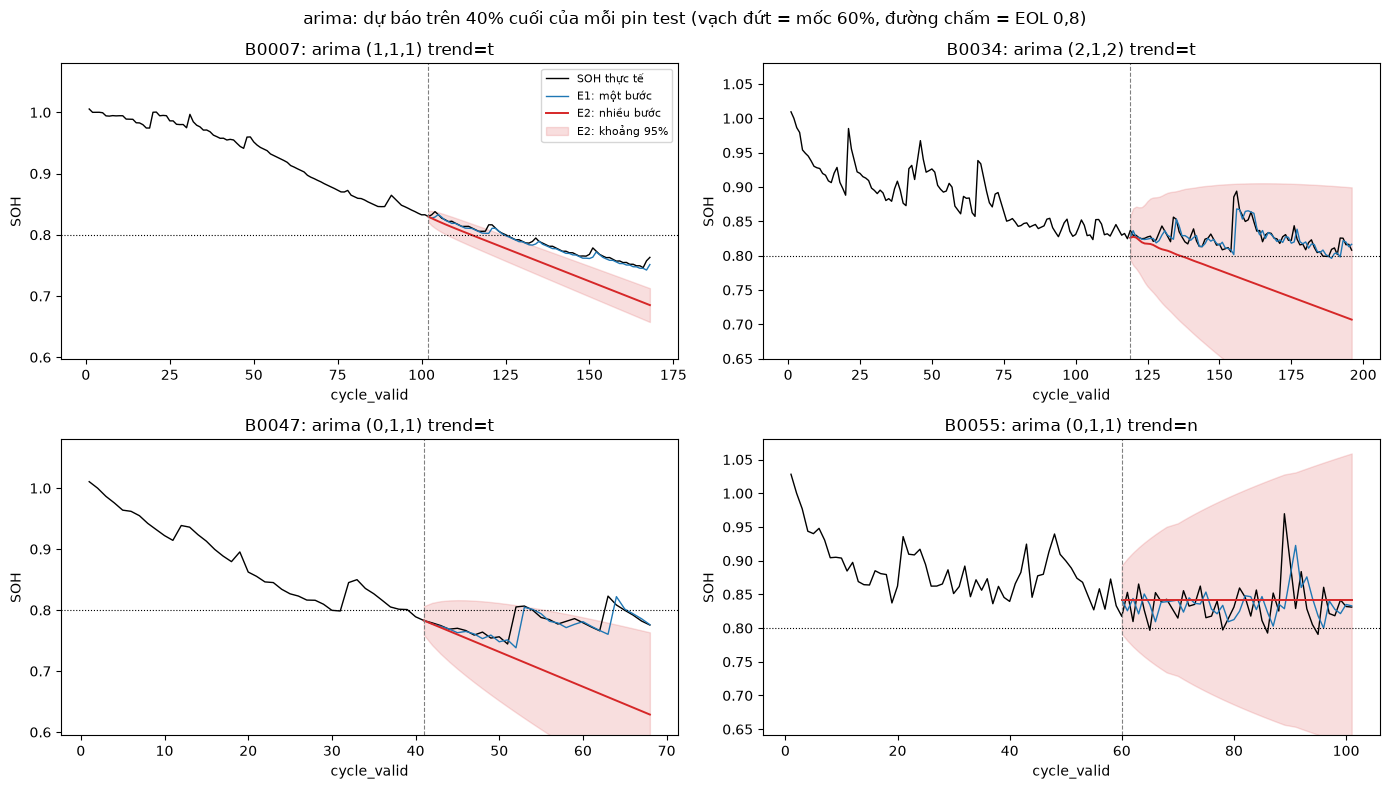

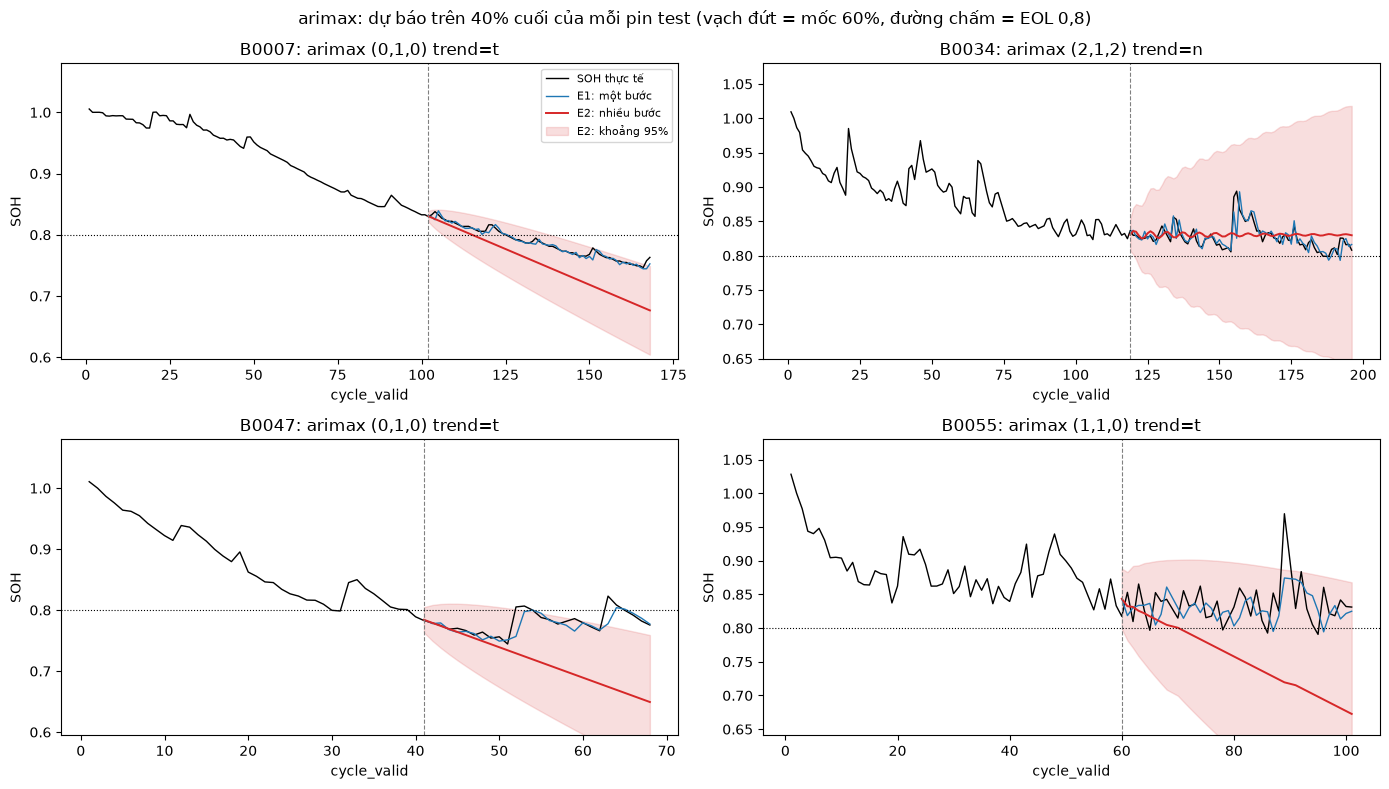

In [18]:
for name in ["arima", "arimax"]:
    fig, axes = plt.subplots(2, 2, figsize=(14, 8))
    for ax, b in zip(axes.flat, TEST_IDS):
        full = rows[rows.battery_id == b]
        p = all_pred[(all_pred.model == name) & (all_pred.battery_id == b)]
        e1, e2 = p[p.scenario == "E1"], p[p.scenario == "E2"]
        ax.plot(full.cycle_valid, full.soh, color="k", lw=1, label="SOH thực tế")
        ax.plot(e1.cycle_valid, e1.y_pred, color="tab:blue", lw=1, label="E1: một bước")
        ax.plot(e2.cycle_valid, e2.y_pred, color="tab:red", lw=1.4, label="E2: nhiều bước")
        ax.fill_between(e2.cycle_valid, e2.y_lower, e2.y_upper, color="tab:red", alpha=0.15, label="E2: khoảng 95%")
        ax.axvline(e1.cycle_valid.min(), color="gray", ls="--", lw=0.8)
        ax.axhline(EOL_SOH, color="k", ls=":", lw=0.8)
        f = fits[(b, name)]
        ax.set_title(f"{b}: {name} ({f['order'][0]},1,{f['order'][2]}) trend={f['trend']}")
        ax.set_ylim(max(0.5, full.soh.min() - 0.15), 1.08)
        ax.set_xlabel("cycle_valid")
        ax.set_ylabel("SOH")
    axes[0, 0].legend(fontsize=8)
    fig.suptitle(f"{name}: dự báo trên 40% cuối của mỗi pin test (vạch đứt = mốc 60%, đường chấm = EOL 0,8)")
    fig.tight_layout()
    fig.savefig(FIG / f"arima_05_forecast_{name}.png", dpi=150)
    plt.show()

## 8. Xuất file dự báo

`reports/predictions/arima.csv` chứa hai mô hình, `arima` và `arimax` (cả hai biến ngoại sinh, đúng thiết kế Go.md 5b.8), mỗi mô hình 213 dòng × 2 kịch bản.
`arimax_rest` chỉ dùng để phân tích trong notebook này, không xuất ra, để bảng so sánh chung không bị nhiều biến thể của cùng một thuật toán.
Không chọn mô hình theo kết quả trên tập test: cả hai mô hình đã định trước đều được xuất.

In [19]:
out = all_pred[all_pred.model.isin(["arima", "arimax"])].sort_values(["model", "scenario"] + KEYS).reset_index(drop=True)
evaluate(out)                           # chạy lại bộ kiểm tra của protocol trên đúng file sẽ ghi
out.to_csv(PRED / "arima.csv", index=False)
print(f"{len(out)} dòng -> {(PRED / 'arima.csv').relative_to(ROOT).as_posix()}")
out.groupby(["model", "scenario"]).size()

852 dòng -> reports/predictions/arima.csv


model   scenario
arima   E1          213
        E2          213
arimax  E1          213
        E2          213
dtype: int64

## 9. Kết luận (RQ3)

Các con số dưới đây đọc từ các bảng ở mục 4–7 của notebook này.

1. **Box-Jenkins:** mọi chuỗi SOH cần **d = 1**. Mô hình được chọn đều có bậc thấp (p, q ≤ 2), phần lớn có drift âm, tức SOH mất trung bình khoảng 0,15–0,57 điểm % mỗi chu kỳ
   (cột `drift` ở mục 6). Phần dư qua Ljung-Box ở 7/8 pin train và 4/4 pin test; ngoại lệ là B0018, giải thích ở mục 5.
2. **Không cần SARIMA:** không có lag mùa vụ chung, khoảng cách giữa các lần nghỉ dài không cố định. Biến động "răng cưa" do hồi phục sau khi nghỉ được mô hình hoá bằng
   biến ngoại sinh. Trong `arimax_rest`, hệ số `log1p(rest_before_h)` dương ở cả 4 pin test và có ý nghĩa ở mức 5% (mục 6).
3. **E1 (một bước):** cả ba mô hình ARIMA đều có RMSE gộp thấp hơn naive persistence. Thêm `log1p(rest_before_h)` giúp nhiều nhất, vì mô hình dự báo được bước nhảy ngay
   tại chu kỳ sau lần nghỉ dài. Thêm `Rct_ohm` không cải thiện thêm về RMSE. Riêng B0007 (chuỗi trơn, ít răng cưa) thì naive vẫn tốt hơn một chút. Khoảng dự báo 95% của E1
   chứa khoảng 92–94% giá trị thực, tức đã được hiệu chỉnh tốt.
4. **E2 (nhiều bước) là điểm yếu của ARIMA:** RMSE gộp **kém hơn naive** và R² âm. Lý do đúng như Go.md 5b dự đoán: với d = 1, dự báo dài hạn là một đường thẳng theo drift
   ước lượng trên 60% đầu. Pin nào suy giảm nhanh lúc đầu rồi chững lại (B0034, B0047) thì đường drift đi xuống quá dốc. Pin nào AIC chọn `trend = n` thì dự báo đi ngang.
   Vì vậy kết quả E2 phụ thuộc mạnh vào việc có drift hay không, và khoảng 95% của `arima` ở E2 chỉ chứa khoảng 74% giá trị thực.
5. **RUL:** `arima` báo EOL **sớm** hơn thực tế ở B0007 và B0034 (cảnh báo sớm, an toàn nhưng gây thay pin sớm), và không chạm 0,8 ở B0055. Xem bảng RUL ở mục 7.

⇒ **Trả lời RQ3:** lịch sử của chính pin đủ để dự báo **ngắn hạn** (một chu kỳ tới) tốt hơn baseline, nhất là khi thêm thời gian nghỉ làm biến ngoại sinh.
ARIMA **không** phù hợp để dự báo dài hạn hay RUL, vì là mô hình tuyến tính (Chap 5, tr. 51) và không bắt được "đầu gối" hay đoạn chững lại của đường suy giảm.

**Đầu ra:**
- `reports/predictions/arima.csv`: 852 dòng = 2 mô hình (`arima`, `arimax`) × 2 kịch bản × 213 dòng đánh giá, đúng định dạng `PRED_COLS`, đã qua `evaluate()`.
- `reports/figures/arima_01_series.png`, `arima_02_acf_level_vs_diff.png`, `arima_03_acf_pacf_diff.png`, `arima_04_resid_acf_train.png`,
  `arima_05_forecast_arima.png`, `arima_05_forecast_arimax.png`.